# Function 1 - Week 6: Exploration review

Review of measured outputs and input coverage through the **Week 5 return, received on 30 October 2026 at 14:57 GMT**.

The independent official snapshot contains **10 initial observations and five returned queries (15 rows)**. All 2 input settings lie in `[0, 1)`. Larger signed outputs are better. Earlier snapshots and separate cohort analyses retain their historical evidence.

The latest output is **-1.38635890998e-94**, **rank 11/15 (1 = highest output)**. It does not improve the prior incumbent of **7.7108751145e-16**. Original inputs and outputs remain at full precision in the local CSV and structured result record.


In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from plot_helpers import (
    PLOT_CONFIG, plot_sampling_gaps,
    plot_observed_terrain, plot_fixed_exploration_progression,
)
function_shared_dir = shared_dir.parent / "Function_1" / "FunctionSpecificShared"
if str(function_shared_dir) not in sys.path:
    sys.path.insert(0, str(function_shared_dir))

from function_1_plots import plot_output_number_line
from function_1_model_helpers import signed_log
print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Settings for this run. Keep the saved planning coordinates at full precision.
FUNCTION_NUMBER = 1
CURRENT_WEEK = 6
INPUT_COLUMNS = ["x1", "x2"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1}

ANALYSIS_DIR = Path.cwd().resolve()
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"

FIRST_PLAN_WEEK = 2
PORTAL_DECIMALS = 6
PLANNED_QUERIES = pd.DataFrame([
    [0.15308205385104573, 0.13395525138390008],
    [0.7818589422435338, 0.0256071460565101],
    [0.12954929624948736, 0.822189245547224],
    [0.9121401448788213, 0.8617829948823881],
], columns=INPUT_COLUMNS)

SAMPLING_GAP_SIZE = (7.6 * 0.75, 6.1 * 0.75)
TERRAIN_SETTINGS = dict(
    relief=0.16, width=850, height=560,
    camera=dict(eye=dict(x=-1.05, y=-1.35, z=0.9)),
    show_reset=True,
)
TERRAIN_SCALE = 1e-200
TERRAIN_TICKS = (-1e-3, 0.0, 1e-15)
WEEK_DIR = ANALYSIS_DIR.parent


In [3]:
# Validate the snapshot before plotting it.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,y,output_rank
14,round-05,5,0.91214,0.861783,-1.386359e-94,11


Latest recorded submission: round 5 (1 new output).
Compared with 14 earlier observations (15 outputs in total).
Earlier output range: [-0.00550934555381, 7.7108751145e-16].

round-05: y = -1.38635890998e-94 (negative); rank 11/15 (1 = highest output).
Inputs: x1 = 0.91214, x2 = 0.861783
Within the earlier output range. Magnitude is 91.6 orders below the earlier largest.


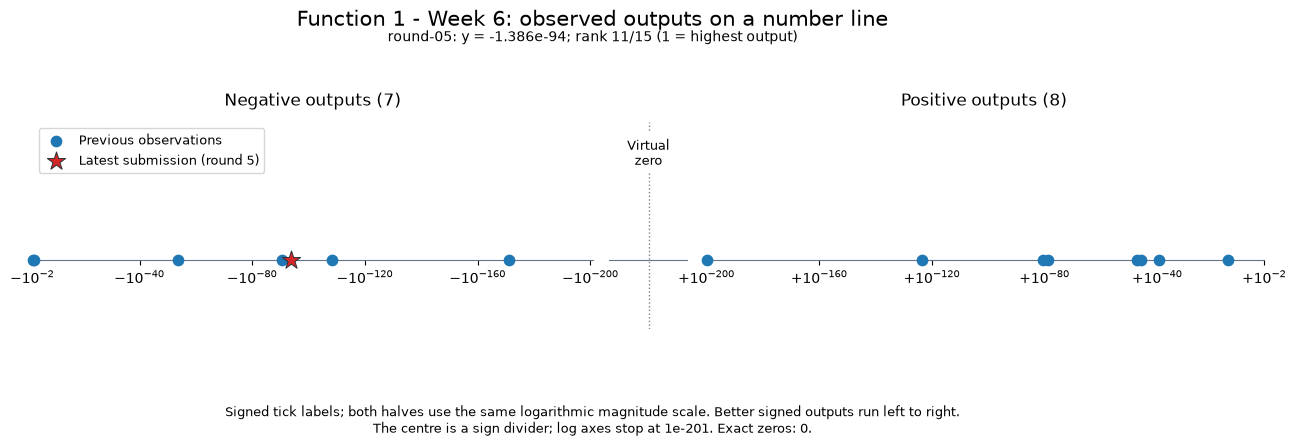

In [4]:
# Signed outputs on matching logarithmic magnitude scales.
plot_output_number_line(
    review, title=f"{TITLE}: observed outputs on a number line",
    save_to=FIGURES_DIR / "output-number-line.png",
)

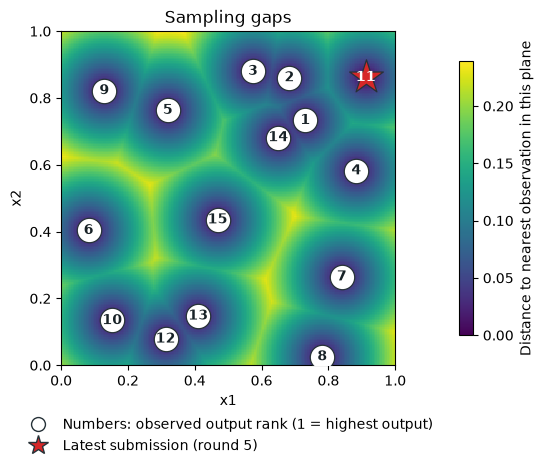

In [5]:
# Measured ranks and sampling gaps in the two-input square.
plot_sampling_gaps(
    review["plot_data"], pair=INPUT_COLUMNS,
    highlight=review["latest_mask"],
    highlight_label=f"Latest submission (round {review['latest_round']})",
    figsize=SAMPLING_GAP_SIZE, save_to=FIGURES_DIR / "sampling-gaps.png",
)

In [6]:
# The terrain joins observed signed-log heights; it does not fit a model.
terrain_fig = plot_observed_terrain(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(),
    title=f"Function {FUNCTION_NUMBER}: observed-output terrain ({len(review['data'])} samples)",
    heights=signed_log(review["outputs"].to_numpy(), scale=TERRAIN_SCALE),
    height_axis=dict(title="Output y (signed log)", tickmode="array",
        tickvals=signed_log(TERRAIN_TICKS, scale=TERRAIN_SCALE),
        ticktext=[f"{value:.0e}" if value else "0" for value in TERRAIN_TICKS]),
    height_description="signed-log heights", save_to=FIGURES_DIR / "observed-output-terrain.html",
    **TERRAIN_SETTINGS,
)
terrain_fig.show(config={**PLOT_CONFIG, "responsive": TERRAIN_SETTINGS["width"] is None})

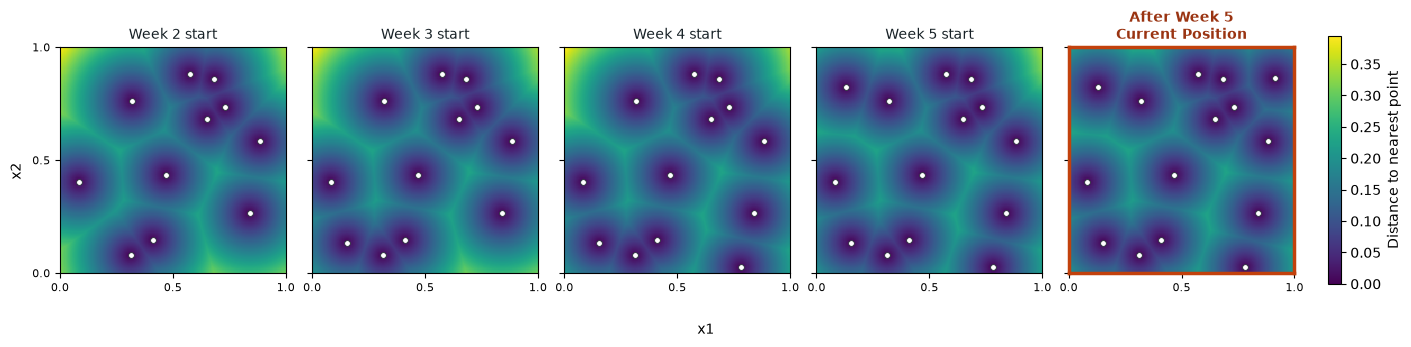

In [7]:
# Show the saved plan against recorded history; no optimisation is run here.
plot_fixed_exploration_progression(
    review["data"], PLANNED_QUERIES, current_week=CURRENT_WEEK,
    first_plan_week=FIRST_PLAN_WEEK,
    save_to=FIGURES_DIR / "fixed-exploration-progression.png",
)

In [8]:
# The completed shortlist returns an empty table; no next query is implied.
remaining_plan = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK,
    first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
display(remaining_plan.style.format({
    column: f"{{:.{PORTAL_DECIMALS}f}}" for column in INPUT_COLUMNS
}))

,x1,x2,Portal input
Week,,,


In [9]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

prepared = prepare_weekly_observation_review(review)


### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [10]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(formatter="{:.12g}", na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,7.7108751145e-16,Not applicable
Round 1,-0.00550934555381,7.7108751145e-16,-0.00550934555381
Round 2,-4.0577449722e-109,7.7108751145e-16,-7.7108751145e-16
Round 3,1.97281177559e-200,7.7108751145e-16,-7.7108751145e-16
Round 4,-9.54589035235e-172,7.7108751145e-16,-7.7108751145e-16
Round 5,-1.38635890998e-94,7.7108751145e-16,-7.7108751145e-16


### Saved Week 5 forecast at the submitted input

Read the preserved submission selection record without refitting. Posterior SD is model dependent; one forecast error does not establish calibration. UCB is a selection score, not a measured return.

In [11]:
# Read the saved selection record at the actual submitted input; no model is refitted.
stage_dir = shared_dir.parent.parent
selection_path = stage_dir / "submissions/Week_05/proposals.json"
if hashlib.sha256(selection_path.read_bytes()).hexdigest() != "6ca900244a2c11ab030075a37c7aae25ef8362651db03ddbc78b7b324cd5bcca":
    raise ValueError("The historical Week 5 selection record has changed.")
selection = next(row for row in json.loads(selection_path.read_text(encoding="utf-8"))["candidates"]
                 if row["function"] == FUNCTION_NUMBER)
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
if not np.array_equal(actual_point, np.asarray(selection["point"], dtype=float)):
    raise ValueError("Saved forecast coordinates do not match the returned query.")
historical_forecast = dict(selection.get("model_prediction") or {})
historical_forecast["data_scope"] = selection["data_scope"]
historical_forecast["actual_output"] = float(prepared["latest"][OUTPUT_COLUMN])
if "predicted_output" in historical_forecast:
    historical_forecast["actual_minus_prediction"] = (
        historical_forecast["actual_output"] - historical_forecast["predicted_output"])
else:
    historical_forecast["forecast_status"] = "Not applicable: fixed coverage selection"
display(pd.Series(historical_forecast))


data_scope                     official_fixed_coverage_plan
actual_output                                          -0.0
forecast_status    Not applicable: fixed coverage selection
dtype: object

### What the return adds

The final fixed coverage query returned a negative, non-zero output of very small magnitude. Signed output remains the optimisation objective; small magnitude does not imply a better signed score. The four-point coverage shortlist is now complete. Week 6 needs a fresh decision using the measured evidence; there is no saved next coverage point.

In [12]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
print(json.dumps(observation_summary, indent=2))


{
  "function": 1,
  "week": 6,
  "observations": 15,
  "latest_id": "round-05",
  "latest_output": -1.3863589099829094e-94,
  "latest_rank": 11,
  "rank_definition": "1 = highest output",
  "best_id": "initial-003",
  "best_observed_output": 7.710875114502849e-16,
  "positive_outputs": 8,
  "negative_outputs": 7,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": 7.710875114502849e-16,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": -0.00550934555381189,
      "best_y": 7.710875114502849e-16,
      "change_vs_prior_best": -0.005509345553812661
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": -4.0577449722040024e-109,
      "best_y": 7.710875114502849e-16,
      "change_vs_prior_best": -7.710875114502849e-16
    },
    {
      "source_round": 3,
      "stage": "Round 3"

### Course lifecycle for this review

1. **Define the goal and scope** — review round 5 for the project owner and prepare evidence for the Week 6 decision; success means a reconciled return and an accurate descriptive review.
2. **Gather the data** — use the retained 30 October results email, original cumulative attachments and independent official CSV snapshot.
3. **Explore the data** — inspect measured ranks, progress and coverage or full input profiles.
4. **Clean and preprocess the data** — validate dimensions, bounds, finite values and round counts; preserve all rows and full float64 precision.
5. **Select and engineer features** — retain the existing ordered input coordinates; no engineered features are required.
6. **Define the machine-learning task** — continuous black-box maximisation remains the task; this notebook provides descriptive evidence.
7. **Partition the data** — not applicable: no new model is fitted or validated in this observation review.
8. **Select and train candidate methods** — not applicable: any Week 6 model comparison is separate work.
9. **Evaluate and interpret the results** — compare the measured return with earlier outputs, the prior incumbent and the saved forecast where one informed selection.
10. **Deploy and iterate** — no deployment applies; carry this evidence into the next query review. Eight query opportunities remain, including Week 6; this notebook submits no query.
